In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import re
import logging
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder , PowerTransformer
from sklearn.impute import SimpleImputer , KNNImputer


In [2]:
warnings.filterwarnings('ignore')
sns.set_style('darkgrid')

In [3]:
file_path = "employability.xlsx"
excel = pd.ExcelFile(file_path)
print(excel.sheet_names)

['Transactions_Raw', 'Customers_Raw', 'Marketing_Raw', 'Inventory_Raw']


In [4]:
transac_df = pd.read_excel(file_path, sheet_name='Transactions_Raw')
customer_df = pd.read_excel(file_path, sheet_name='Customers_Raw')
market_df = pd.read_excel(file_path, sheet_name='Marketing_Raw')
inventory_df = pd.read_excel(file_path, sheet_name='Inventory_Raw')

In [5]:
inventory_df = pd.read_excel(file_path, sheet_name='Inventory_Raw')

In [6]:
print(transac_df.head())
print("-"*30)
print(customer_df.head())
print("-"*30)
print(market_df.head())
print("-"*30)
print(inventory_df.head())

  Order_ID Customer_ID  Order_Date  Total_Sales
0  ORD1000     CUST195  2025-13-01        -45.0
1  ORD1001         NaN  2025-13-01          0.0
2  ORD1002         NaN         NaN        150.0
3  ORD1003     CUST184         NaN         85.0
4  ORD1004     CUST168  12/02/2025        120.0
------------------------------
  Cust_ID  Customer_Name            Email       State
0  CUST001     Dana Blue              NaN      Oregon
1  CUST002    Fred Stone              NaN  Washington
2  CUST003     Bob White  user2@email.com  washington
3  CUST004     Bob White              NaN  washington
4  CUST005   Charlie Tan  user4@email.com  California
------------------------------
  Campaign_ID           Channel        Date    Reach CTR (%)
0        MKT1  YouTube Campaign         NaN   5000.0     NaN
1        MKT2             Email  2025/15/02   -500.0      4%
2        MKT3      Facebook Ads  2025-02-08  12000.0    0.02
3        MKT4             Email         NaN   5000.0    3.5%
4         NaN  YouTub

In [7]:
print(transac_df.info())
print("-"*30)
print(customer_df.info())
print("-"*30)
print(market_df.info())
print("-"*30)
print(inventory_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Order_ID     300 non-null    object 
 1   Customer_ID  233 non-null    object 
 2   Order_Date   203 non-null    object 
 3   Total_Sales  300 non-null    float64
dtypes: float64(1), object(3)
memory usage: 9.5+ KB
None
------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Cust_ID        205 non-null    object
 1   Customer_Name  205 non-null    object
 2   Email          93 non-null     object
 3   State          205 non-null    object
dtypes: object(4)
memory usage: 6.5+ KB
None
------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column   

In [8]:
print(transac_df.describe())
print("-"*30)
print(customer_df.describe())
print("-"*30)
print(market_df.describe())
print("-"*30)
print(inventory_df.describe())

       Total_Sales
count   300.000000
mean     96.415133
std      77.637991
min     -45.000000
25%      63.750000
50%      99.990000
75%     150.000000
max     200.000000
------------------------------
       Cust_ID  Customer_Name             Email       State
count       205           205                93         205
unique      200             6                90           7
top     CUST103     Dana Blue  user30@email.com  California
freq          2            39                 2          37
------------------------------
              Reach
count    126.000000
mean    6773.809524
std     4541.632809
min     -500.000000
25%     5000.000000
50%     8000.000000
75%    10000.000000
max    12000.000000
------------------------------
         SKU Product_Name  Stock Unit_Price
count     80          100    100        100
unique    80          100      7          7
top     SKU1    Product 1      0        £18
freq       1            1     21         21


In [9]:
customer_df

,Cust_ID,Customer_Name,Email,State
0,CUST001,Dana Blue,NaN,Oregon
1,CUST002,Fred Stone,NaN,Washington
2,CUST003,Bob White,user2@email.com,washington
3,CUST004,Bob White,NaN,washington
4,CUST005,Charlie Tan,user4@email.com,California
...,...,...,...,...
200,CUST103,Eve Gray,NaN,washington
201,CUST076,Dana Blue,NaN,California
202,CUST178,Charlie Tan,user177@email.com,CA
203,CUST031,Eve Gray,user30@email.com,OR


In [10]:
customer_df.columns.tolist


<bound method IndexOpsMixin.tolist of Index(['Cust_ID ', 'Customer_Name', 'Email', 'State'], dtype='object')>

In [11]:
merged_df = transac_df.merge(
    customer_df,
    left_on="Customer_ID",
    right_on="Cust_ID ",
    how="left",
    
)

In [12]:
merged_df["Order_Date"] = pd.to_datetime(
    merged_df["Order_Date"],
    errors="coerce",
    dayfirst=True,
    format="mixed"
)

merged_df['Day'] = merged_df.Order_Date.dt.day
merged_df['Weekday'] = merged_df.Order_Date.dt.weekday
merged_df['Month'] = merged_df.Order_Date.dt.month
merged_df['Year'] = merged_df.Order_Date.dt.year

In [13]:
merged_df

,Order_ID,Customer_ID,Order_Date,Total_Sales,Cust_ID,Customer_Name,Email,State,Day,Weekday,Month,Year
0,ORD1000,CUST195,2025-01-13,-45.0,CUST195,Alice Green,NaN,Washington,13.0,0.0,1.0,2025.0
1,ORD1001,NaN,2025-01-13,0.0,NaN,NaN,NaN,NaN,13.0,0.0,1.0,2025.0
2,ORD1002,NaN,NaT,150.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ORD1003,CUST184,NaT,85.0,CUST184,Bob White,NaN,CA,NaN,NaN,NaN,NaN
4,ORD1004,CUST168,2025-02-12,120.0,CUST168,Charlie Tan,NaN,CA,12.0,2.0,2.0,2025.0
...,...,...,...,...,...,...,...,...,...,...,...,...
297,ORD1295,NaN,NaT,150.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
298,ORD1296,CUST155,2025-01-22,150.0,CUST155,Fred Stone,NaN,California,22.0,2.0,1.0,2025.0
299,ORD1297,CUST019,NaT,-45.0,CUST019,Eve Gray,NaN,CA,NaN,NaN,NaN,NaN
300,ORD1298,CUST089,2025-02-17,120.0,CUST089,Charlie Tan,user88@email.com,Washington,17.0,0.0,2.0,2025.0


In [14]:
merged_df.drop(columns = ['Email'] , inplace = True)

In [15]:
merged_df["Is_Refund"] = (
    merged_df["Total_Sales"] < 0
).astype(int)

In [16]:
merged_df["Is_Zero_Sale"] = (
    merged_df["Total_Sales"] == 0
).astype(int)

In [17]:
state_mapping = {
    "or": "Oregon",
    "oregon": "Oregon",
    "wa": "Washington",
    "washington": "Washington",
    "ca": "California",
    "california": "California"
}

merged_df["State"] = (
    merged_df["State"].str.strip().str.lower()
    .map(state_mapping)
)

In [18]:
inventory_df

,SKU,Product_Name,Stock,Unit_Price
0,SKU1,Product 1,100,$25
1,SKU2,Product 2,-10,€20
2,SKU3,Product 3,9999,£18
3,SKU4,Product 4,100,$30
4,NaN,Product 5,0,$30
...,...,...,...,...
95,SKU96,Product 96,0,AUD$26
96,SKU97,Product 97,9999,USD 28
97,SKU98,Product 98,0,AUD$26
98,SKU99,Product 99,50,$30


In [19]:
market_df

,Campaign_ID,Channel,Date,Reach,CTR (%)
0,MKT1,YouTube Campaign,NaN,5000.0,NaN
1,MKT2,Email,2025/15/02,-500.0,4%
2,MKT3,Facebook Ads,2025-02-08,12000.0,0.02
3,MKT4,Email,NaN,5000.0,3.5%
4,NaN,YouTube Campaign,NaN,-500.0,0.02
...,...,...,...,...,...
145,MKT146,Google Ads,2025/15/02,10000.0,4%
146,MKT147,YouTube Campaign,NaN,5000.0,2%
147,MKT148,InstaAds,2025/15/02,-500.0,3.00%
148,MKT149,YouTube Campaign,2025-01-22,5000.0,0.02


In [20]:
def extract_price(value):

    value = str(value)

    price = re.search(
        r"\d+(?:\.\d+)?",
        value
    )

    if price:
        return float(price.group())

    return np.nan

In [21]:
inventory_df['Price_amount'] = inventory_df['Unit_Price'].apply(extract_price)

In [22]:
def extract_currency(value):

    value = str(value).strip()

    if re.search(r"AUD", value, re.I):
        return "AUD"

    elif re.search(r"USD", value, re.I):
        return "USD"

    elif "€" in value:
        return "EUR"

    elif "£" in value:
        return "GBP"

    elif "$" in value:
        return "USD"

    elif re.search(r"dollars", value, re.I):
        return "USD"

    return "UNKNOWN"


The $ is definitely a dollar sign. However, the issue is that the dollar sign does not uniquely identify the currency.

Several countries use $ as their currency symbol:

Currency

Symbol

US Dollar (USD)

$

Australian Dollar (AUD)

$

Canadian Dollar (CAD)

$

Singapore Dollar (SGD)

$

New Zealand Dollar (NZD)

$

In [23]:
inventory_df["Currency"] = (
    inventory_df["Unit_Price"].apply(extract_currency)
)

In [24]:
currency_rates = {

    "USD": 93.4798,
    "AUD": 62.9849,
    "EUR": 102.727,
    "GBP": 123.297

}

In [25]:
inventory_df["Exchange_Rate"] = (
    inventory_df["Currency"].map(currency_rates)
)

inventory_df["Unit_Price_INR"] = (
    inventory_df["Price_amount"] *
    inventory_df["Exchange_Rate"]
)

In [26]:
inventory_df

,SKU,Product_Name,Stock,Unit_Price,Price_amount,Currency,Exchange_Rate,Unit_Price_INR
0,SKU1,Product 1,100,$25,25.0,USD,93.4798,2336.9950
1,SKU2,Product 2,-10,€20,20.0,EUR,102.7270,2054.5400
2,SKU3,Product 3,9999,£18,18.0,GBP,123.2970,2219.3460
3,SKU4,Product 4,100,$30,30.0,USD,93.4798,2804.3940
4,NaN,Product 5,0,$30,30.0,USD,93.4798,2804.3940
...,...,...,...,...,...,...,...,...
95,SKU96,Product 96,0,AUD$26,26.0,AUD,62.9849,1637.6074
96,SKU97,Product 97,9999,USD 28,28.0,USD,93.4798,2617.4344
97,SKU98,Product 98,0,AUD$26,26.0,AUD,62.9849,1637.6074
98,SKU99,Product 99,50,$30,30.0,USD,93.4798,2804.3940


In [27]:
market_df["Reach_Clean"] = market_df["Reach"].where(
    market_df["Reach"] >= 0,
    0
)

In [29]:
inventory_df["Stock"] = pd.to_numeric(
    inventory_df["Stock"],
    errors="coerce"
)

inventory_df.loc[
    inventory_df["Stock"] < 0,
    "Stock"
] = 0

In [30]:
inventory_df["Stock"] = inventory_df["Stock"].replace({
    "ten": "10"
})

inventory_df["Stock"] = pd.to_numeric(
    inventory_df["Stock"],
    errors="coerce"
)

In [31]:
market_df["Reach"] = pd.to_numeric(
    market_df["Reach"],
    errors="coerce"
)

market_df["Reach_Clean"] = market_df["Reach"].where(
    market_df["Reach"] >= 0,
    0
)

In [32]:
market_df["Date"] = pd.to_datetime(
    market_df["Date"],
    errors="coerce",
    dayfirst=True,
    format="mixed"
)

market_df['M_Day'] = market_df.Date.dt.day
market_df['M_Weekday'] = market_df.Date.dt.weekday
market_df['M_Month'] = market_df.Date.dt.month
market_df['M_Year'] = market_df.Date.dt.year

In [33]:

def clean_ctr(value):

    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    has_percent = "%" in value

    number = re.search(
        r"\d+(?:\.\d+)?",
        value
    )

    if number is None:
        return np.nan

    number = float(number.group())

    if has_percent:
        return number

    elif 0 < number < 1:
        return number * 100

    else:
        return number


market_df["CTR_Percent"] = (
    market_df["CTR (%)"].apply(clean_ctr)
)

In [34]:
market_df

,Campaign_ID,Channel,Date,Reach,CTR (%),Reach_Clean,M_Day,M_Weekday,M_Month,M_Year,CTR_Percent
0,MKT1,YouTube Campaign,NaT,5000.0,NaN,5000.0,NaN,NaN,NaN,NaN,NaN
1,MKT2,Email,2025-02-15,-500.0,4%,0.0,15.0,5.0,2.0,2025.0,4.0
2,MKT3,Facebook Ads,2025-02-08,12000.0,0.02,12000.0,8.0,5.0,2.0,2025.0,2.0
3,MKT4,Email,NaT,5000.0,3.5%,5000.0,NaN,NaN,NaN,NaN,3.5
4,NaN,YouTube Campaign,NaT,-500.0,0.02,0.0,NaN,NaN,NaN,NaN,2.0
...,...,...,...,...,...,...,...,...,...,...,...
145,MKT146,Google Ads,2025-02-15,10000.0,4%,10000.0,15.0,5.0,2.0,2025.0,4.0
146,MKT147,YouTube Campaign,NaT,5000.0,2%,5000.0,NaN,NaN,NaN,NaN,2.0
147,MKT148,InstaAds,2025-02-15,-500.0,3.00%,0.0,15.0,5.0,2.0,2025.0,3.0
148,MKT149,YouTube Campaign,2025-01-22,5000.0,0.02,5000.0,22.0,2.0,1.0,2025.0,2.0


In [35]:
inventory_df

,SKU,Product_Name,Stock,Unit_Price,Price_amount,Currency,Exchange_Rate,Unit_Price_INR
0,SKU1,Product 1,100.0,$25,25.0,USD,93.4798,2336.9950
1,SKU2,Product 2,0.0,€20,20.0,EUR,102.7270,2054.5400
2,SKU3,Product 3,9999.0,£18,18.0,GBP,123.2970,2219.3460
3,SKU4,Product 4,100.0,$30,30.0,USD,93.4798,2804.3940
4,NaN,Product 5,0.0,$30,30.0,USD,93.4798,2804.3940
...,...,...,...,...,...,...,...,...
95,SKU96,Product 96,0.0,AUD$26,26.0,AUD,62.9849,1637.6074
96,SKU97,Product 97,9999.0,USD 28,28.0,USD,93.4798,2617.4344
97,SKU98,Product 98,0.0,AUD$26,26.0,AUD,62.9849,1637.6074
98,SKU99,Product 99,50.0,$30,30.0,USD,93.4798,2804.3940


In [36]:
len(inventory_df[inventory_df['Stock'] == 9999])

16

In [37]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       302 non-null    object        
 1   Customer_ID    235 non-null    object        
 2   Order_Date     204 non-null    datetime64[ns]
 3   Total_Sales    302 non-null    float64       
 4   Cust_ID        227 non-null    object        
 5   Customer_Name  227 non-null    object        
 6   State          227 non-null    object        
 7   Day            204 non-null    float64       
 8   Weekday        204 non-null    float64       
 9   Month          204 non-null    float64       
 10  Year           204 non-null    float64       
 11  Is_Refund      302 non-null    int64         
 12  Is_Zero_Sale   302 non-null    int64         
dtypes: datetime64[ns](1), float64(5), int64(2), object(5)
memory usage: 30.8+ KB


In [38]:
numeric_cols = merged_df.select_dtypes(include = np.number).columns.tolist()
categorical_cols = merged_df.select_dtypes(include = 'object').columns.tolist()

In [39]:
numeric_cols

['Total_Sales', 'Day', 'Weekday', 'Month', 'Year', 'Is_Refund', 'Is_Zero_Sale']

In [41]:
imputer_merged = KNNImputer(n_neighbors = 5  , weights = 'distance')
merged_df["Total_Sales"] = imputer_merged.fit_transform(merged_df[['Total_Sales']])


In [42]:
numeric_cols

['Total_Sales', 'Day', 'Weekday', 'Month', 'Year', 'Is_Refund', 'Is_Zero_Sale']

In [43]:
merged_df[numeric_cols].isna().sum()

Total_Sales      0
Day             98
Weekday         98
Month           98
Year            98
Is_Refund        0
Is_Zero_Sale     0
dtype: int64

In [45]:
categorical_cols = ["State"]

In [46]:
imputer_merged_c = SimpleImputer(strategy = 'most_frequent')
merged_df[categorical_cols] = imputer_merged_c.fit_transform(merged_df[categorical_cols])

In [47]:
merged_df[categorical_cols].isna().sum()

State    0
dtype: int64

In [48]:
inventory_df

,SKU,Product_Name,Stock,Unit_Price,Price_amount,Currency,Exchange_Rate,Unit_Price_INR
0,SKU1,Product 1,100.0,$25,25.0,USD,93.4798,2336.9950
1,SKU2,Product 2,0.0,€20,20.0,EUR,102.7270,2054.5400
2,SKU3,Product 3,9999.0,£18,18.0,GBP,123.2970,2219.3460
3,SKU4,Product 4,100.0,$30,30.0,USD,93.4798,2804.3940
4,NaN,Product 5,0.0,$30,30.0,USD,93.4798,2804.3940
...,...,...,...,...,...,...,...,...
95,SKU96,Product 96,0.0,AUD$26,26.0,AUD,62.9849,1637.6074
96,SKU97,Product 97,9999.0,USD 28,28.0,USD,93.4798,2617.4344
97,SKU98,Product 98,0.0,AUD$26,26.0,AUD,62.9849,1637.6074
98,SKU99,Product 99,50.0,$30,30.0,USD,93.4798,2804.3940


In [49]:
invent_num_col = inventory_df.select_dtypes(include= np.number).columns.tolist()
invent_cat_col = inventory_df.select_dtypes(include = 'object').columns.tolist()

In [50]:
invent_num_col , invent_cat_col

(['Stock', 'Price_amount', 'Exchange_Rate', 'Unit_Price_INR'],
 ['SKU', 'Product_Name', 'Unit_Price', 'Currency'])

In [51]:
inventory_df.isna().sum()

SKU               20
Product_Name       0
Stock              1
Unit_Price         0
Price_amount       0
Currency           0
Exchange_Rate      0
Unit_Price_INR     0
dtype: int64

In [52]:
inventory_df['Stock'] = inventory_df.Stock.fillna(inventory_df.Stock.mean())

In [53]:
data = 'SKU12 '
data.strip().upper()

'SKU12'

In [54]:
miss = inventory_df["SKU"].isna()
print(miss)

0     False
1     False
2     False
3     False
4      True
      ...  
95    False
96    False
97    False
98    False
99     True
Name: SKU, Length: 100, dtype: bool


In [55]:


inventory_df["Product_Number"] = (
    inventory_df["Product_Name"]
    .str.extract(r"(\d+)")
)

inventory_df["SKU_Clean"] = inventory_df["SKU"].str.strip().str.upper()

missing = inventory_df["SKU_Clean"].isna()

inventory_df.loc[missing, "SKU_Clean"] = (
    "SKU" +
    inventory_df.loc[missing, "Product_Number"]
)

In [56]:
inventory_df

,SKU,Product_Name,Stock,Unit_Price,Price_amount,Currency,Exchange_Rate,Unit_Price_INR,Product_Number,SKU_Clean
0,SKU1,Product 1,100.0,$25,25.0,USD,93.4798,2336.9950,1,SKU1
1,SKU2,Product 2,0.0,€20,20.0,EUR,102.7270,2054.5400,2,SKU2
2,SKU3,Product 3,9999.0,£18,18.0,GBP,123.2970,2219.3460,3,SKU3
3,SKU4,Product 4,100.0,$30,30.0,USD,93.4798,2804.3940,4,SKU4
4,NaN,Product 5,0.0,$30,30.0,USD,93.4798,2804.3940,5,SKU5
...,...,...,...,...,...,...,...,...,...,...
95,SKU96,Product 96,0.0,AUD$26,26.0,AUD,62.9849,1637.6074,96,SKU96
96,SKU97,Product 97,9999.0,USD 28,28.0,USD,93.4798,2617.4344,97,SKU97
97,SKU98,Product 98,0.0,AUD$26,26.0,AUD,62.9849,1637.6074,98,SKU98
98,SKU99,Product 99,50.0,$30,30.0,USD,93.4798,2804.3940,99,SKU99


In [57]:
inventory_df['SKU'] = inventory_df['SKU_Clean']
inventory_df.drop(columns = ['SKU_Clean'] , inplace = True)

In [58]:
market_df.isna().sum()

Campaign_ID    30
Channel         0
Date           44
Reach          24
CTR (%)        18
Reach_Clean     0
M_Day          44
M_Weekday      44
M_Month        44
M_Year         44
CTR_Percent    18
dtype: int64

In [59]:
market_df.shape

(150, 11)

In [60]:
market_df.isna().sum()

Campaign_ID    30
Channel         0
Date           44
Reach          24
CTR (%)        18
Reach_Clean     0
M_Day          44
M_Weekday      44
M_Month        44
M_Year         44
CTR_Percent    18
dtype: int64

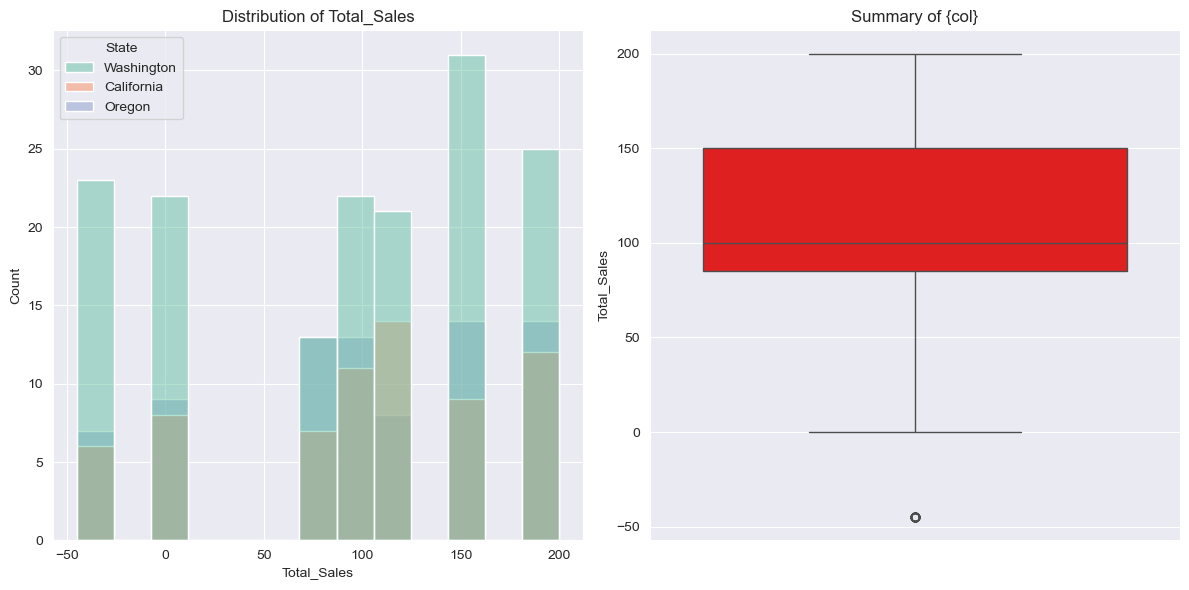

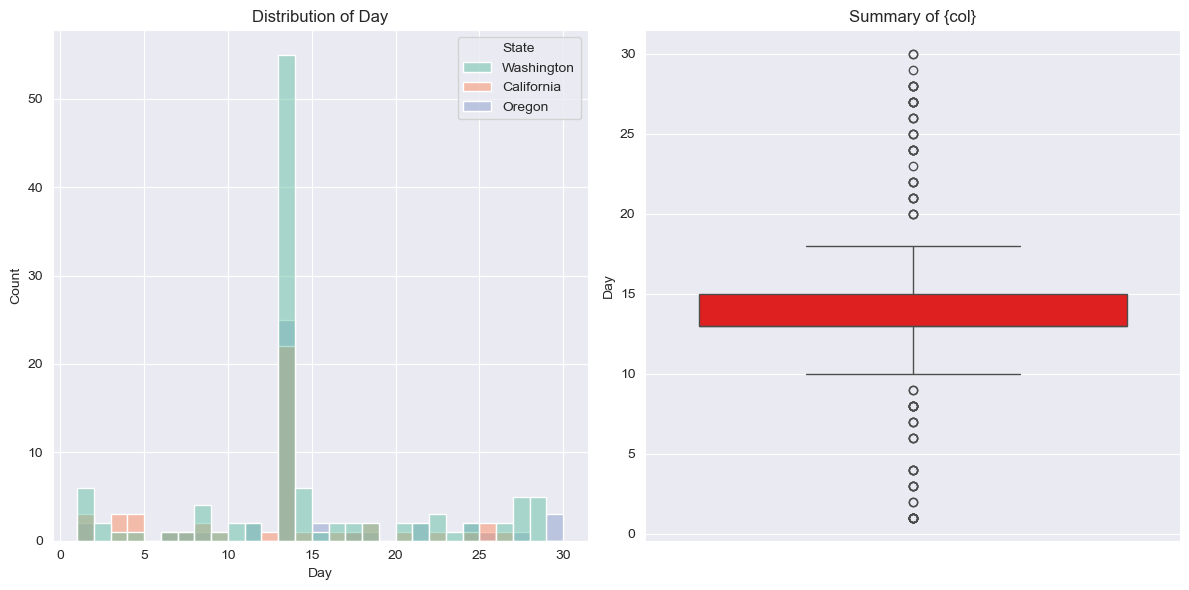

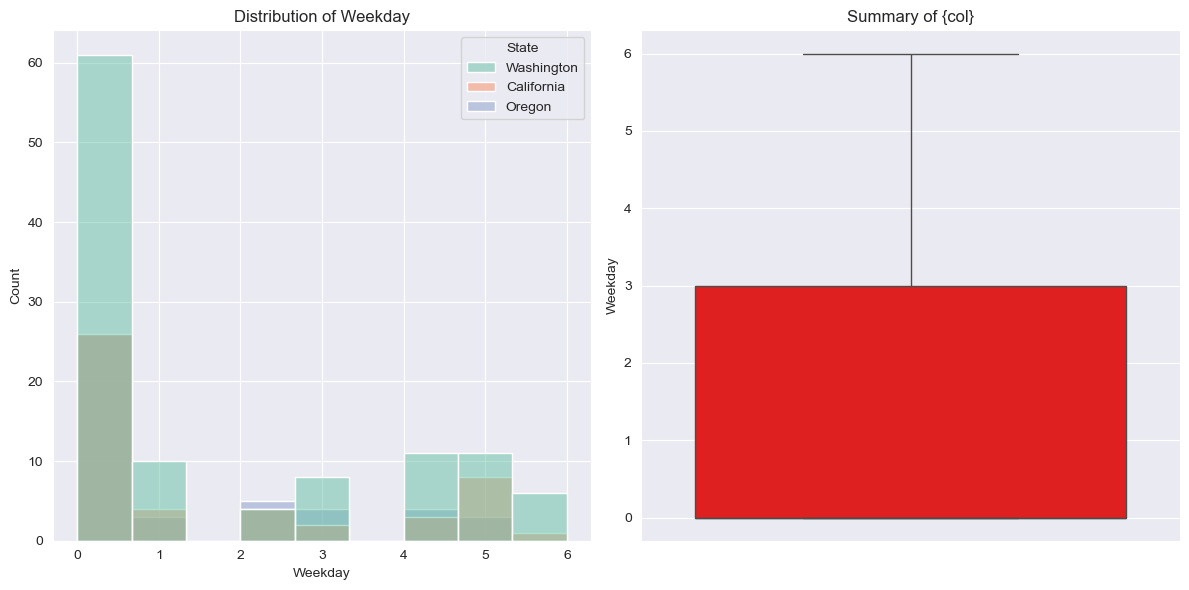

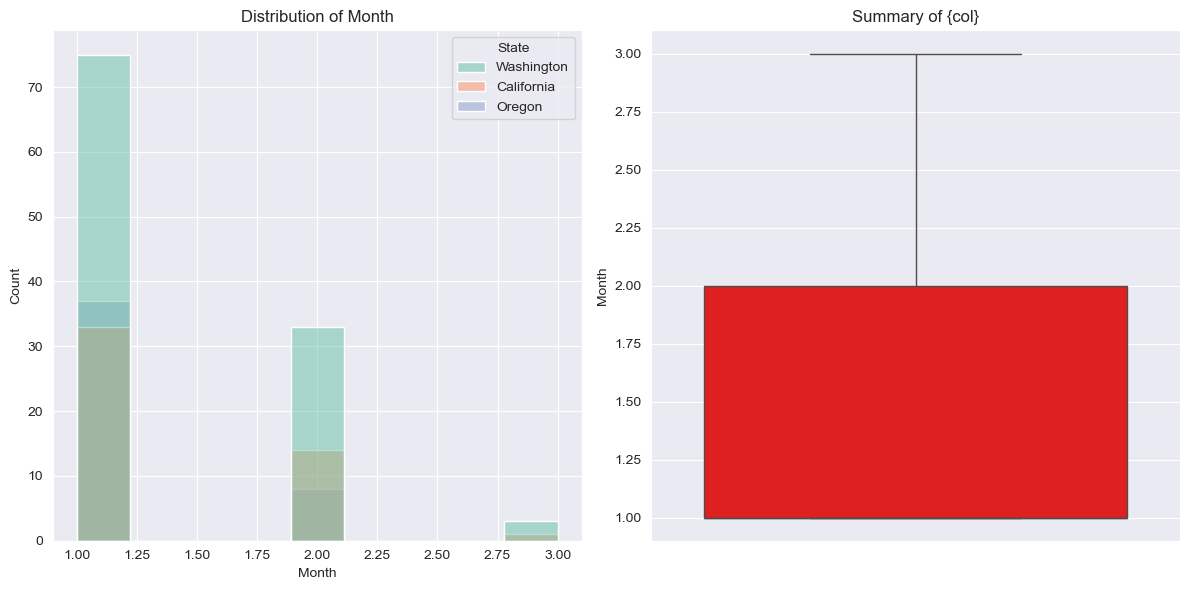

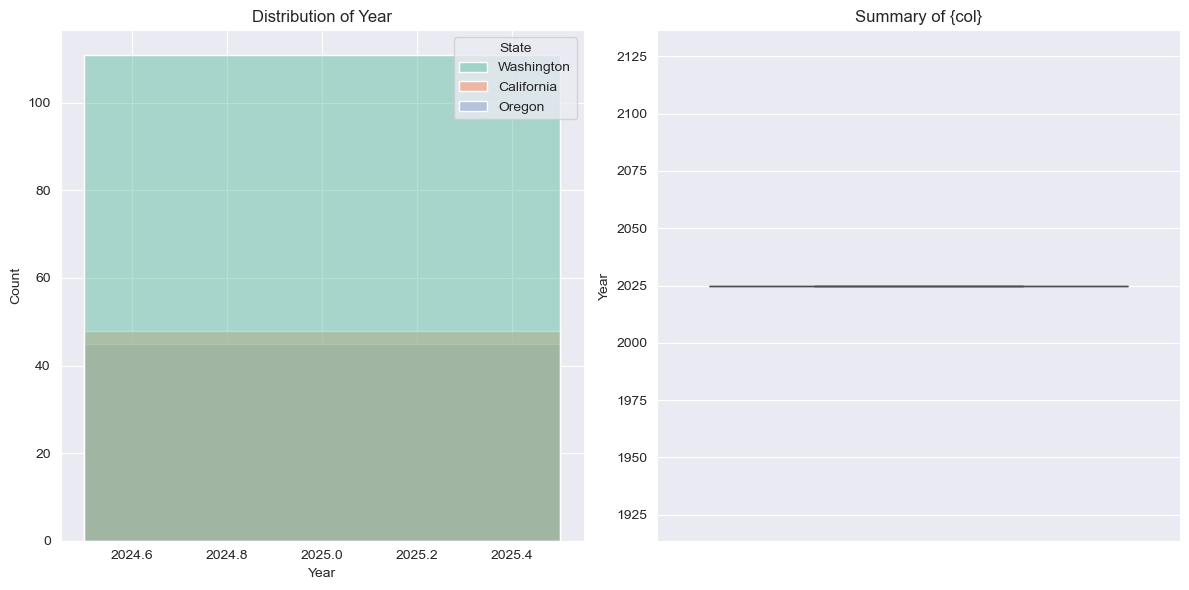

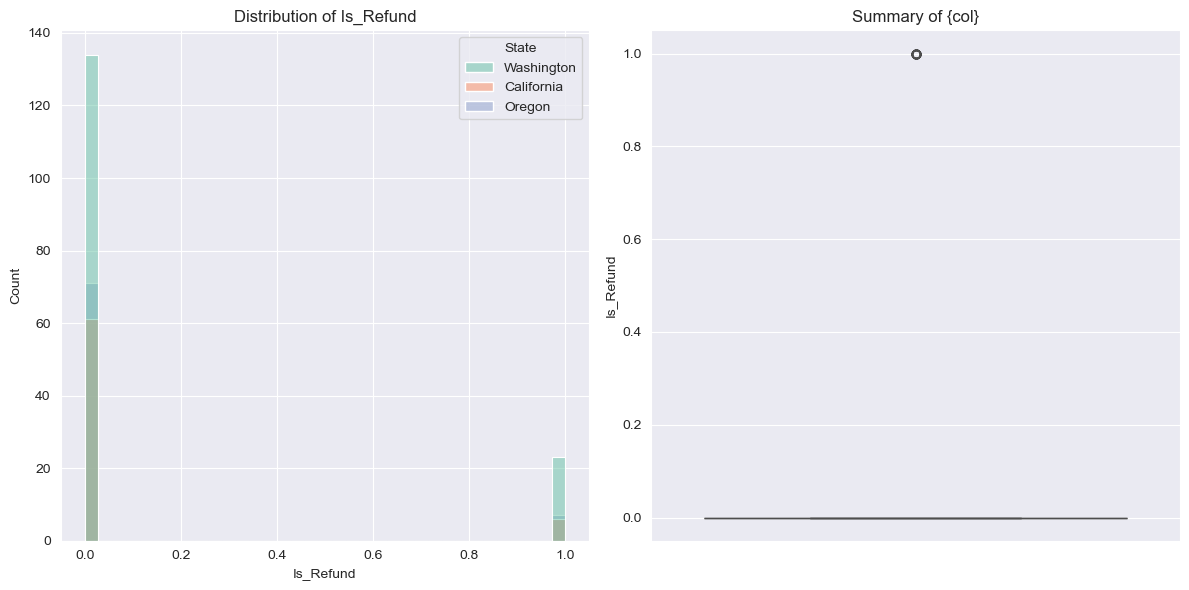

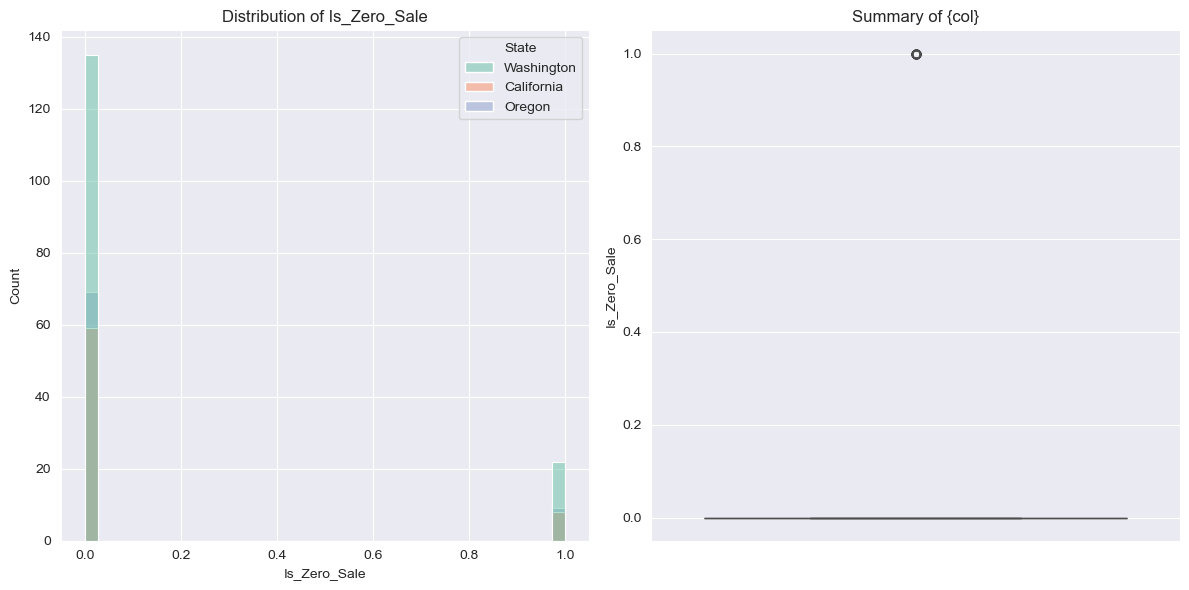

In [61]:
for col in numeric_cols:
    plt.figure(figsize = (12, 6))
    plt.subplot(1,2 , 1)
    sns.histplot(data = merged_df , x = col , hue = 'State' , palette = 'Set2')
    plt.title(f"Distribution of {col}")

    plt.subplot(1,2,2)
    sns.boxplot(merged_df[col] , color = 'red')
    plt.title("Summary of {col}")

    plt.tight_layout()
    plt.show()

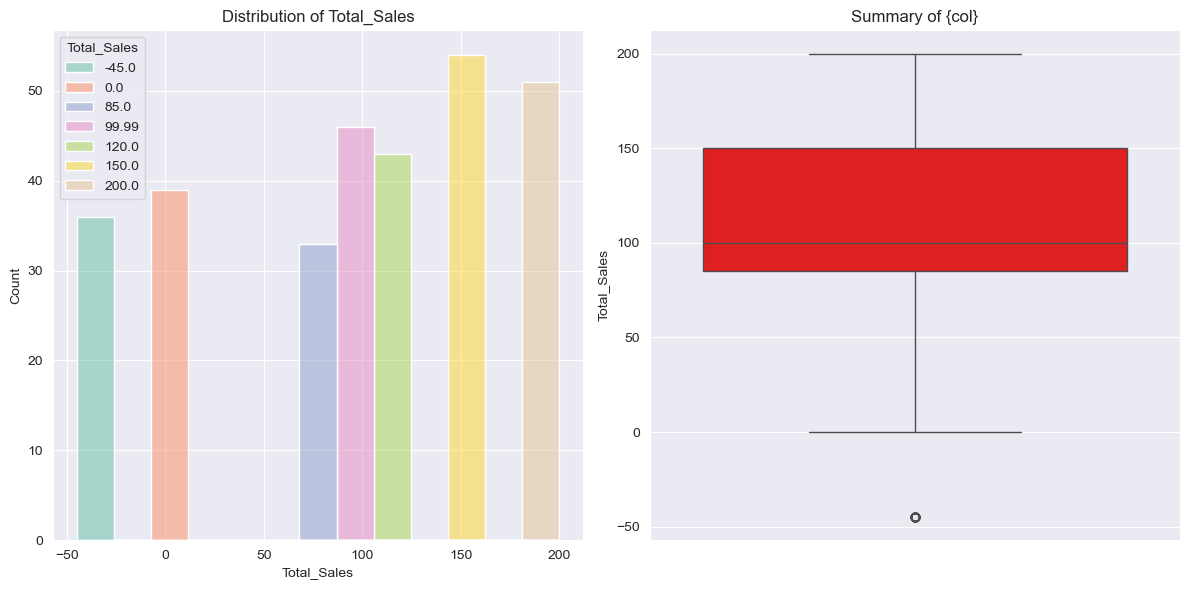

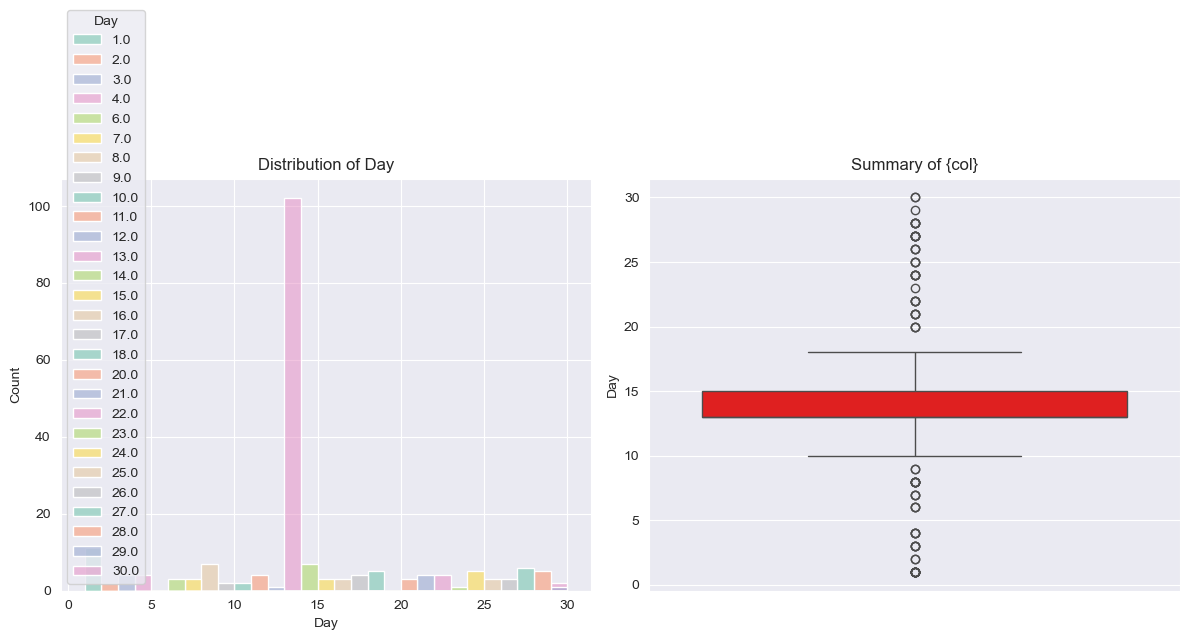

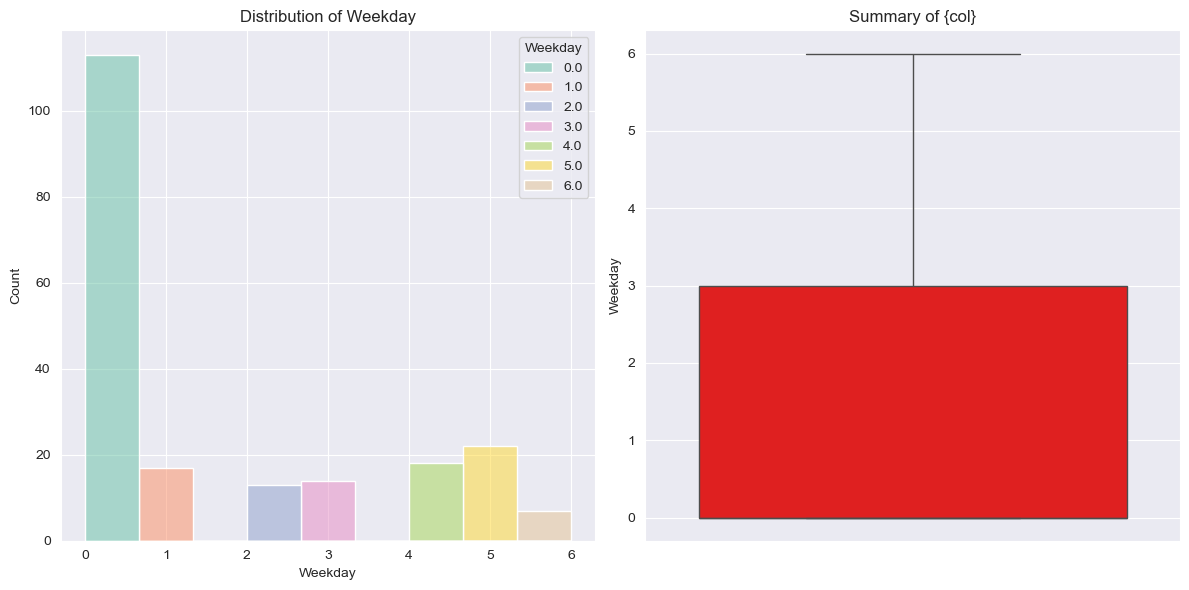

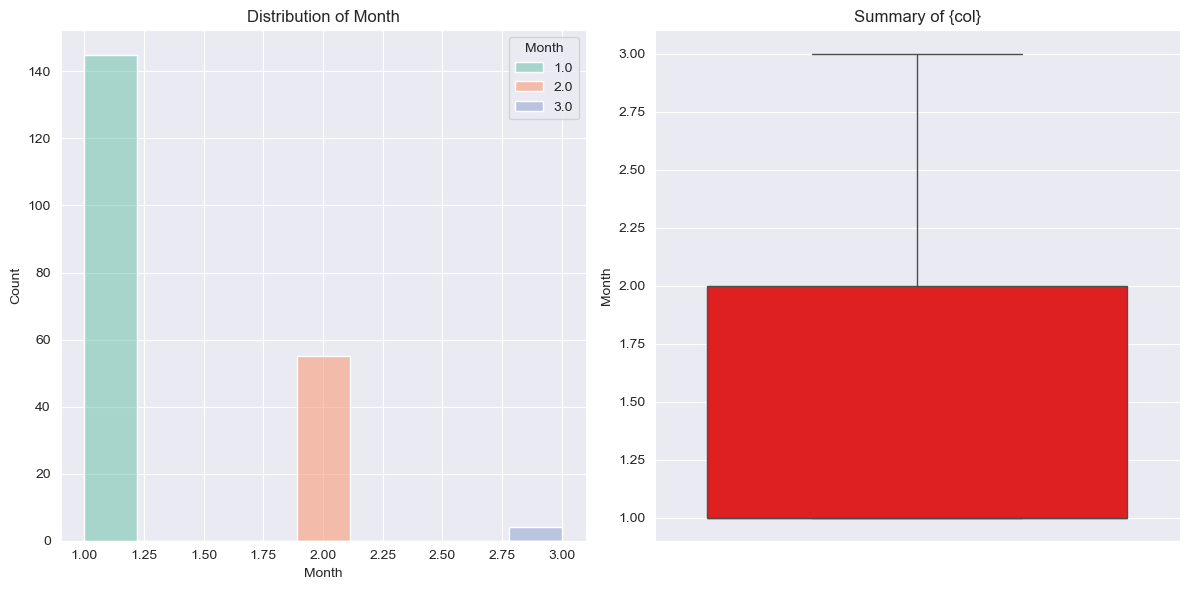

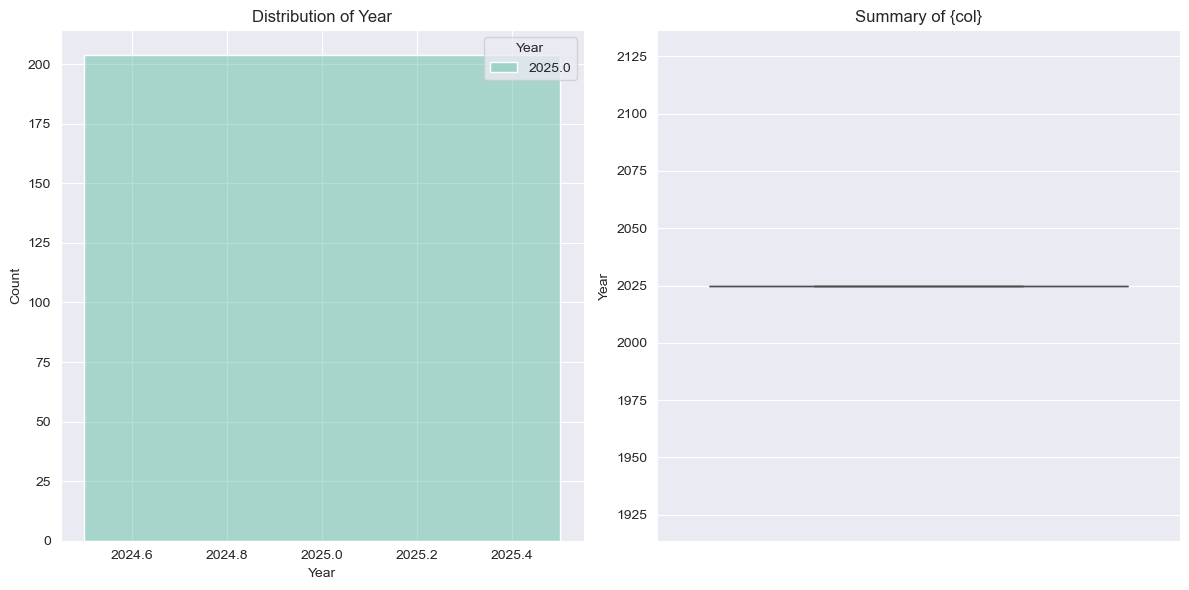

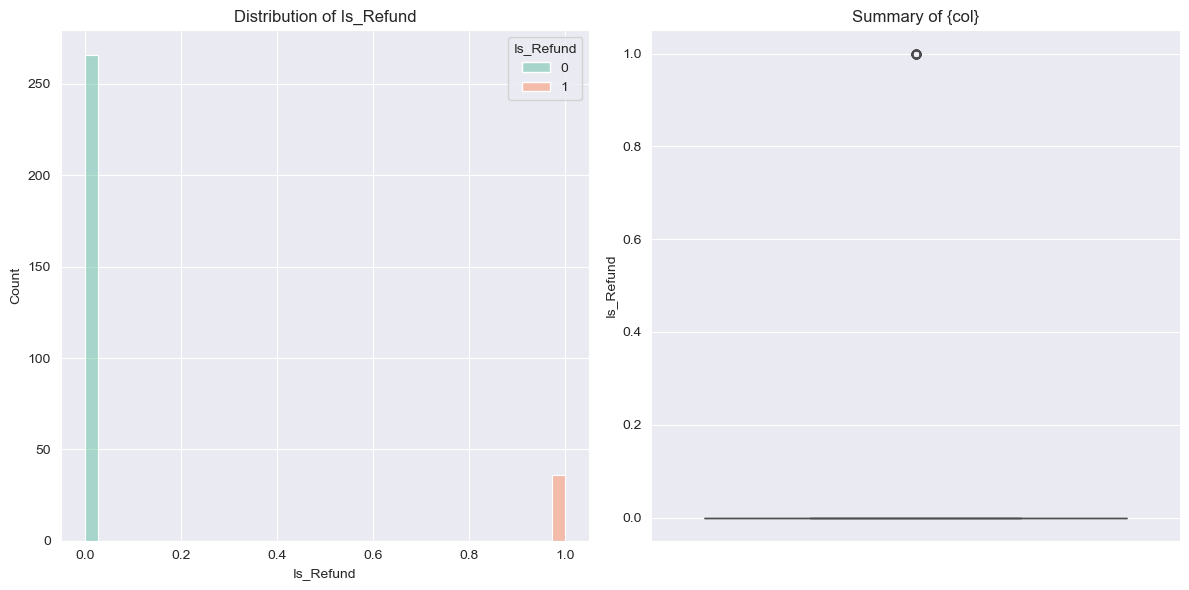

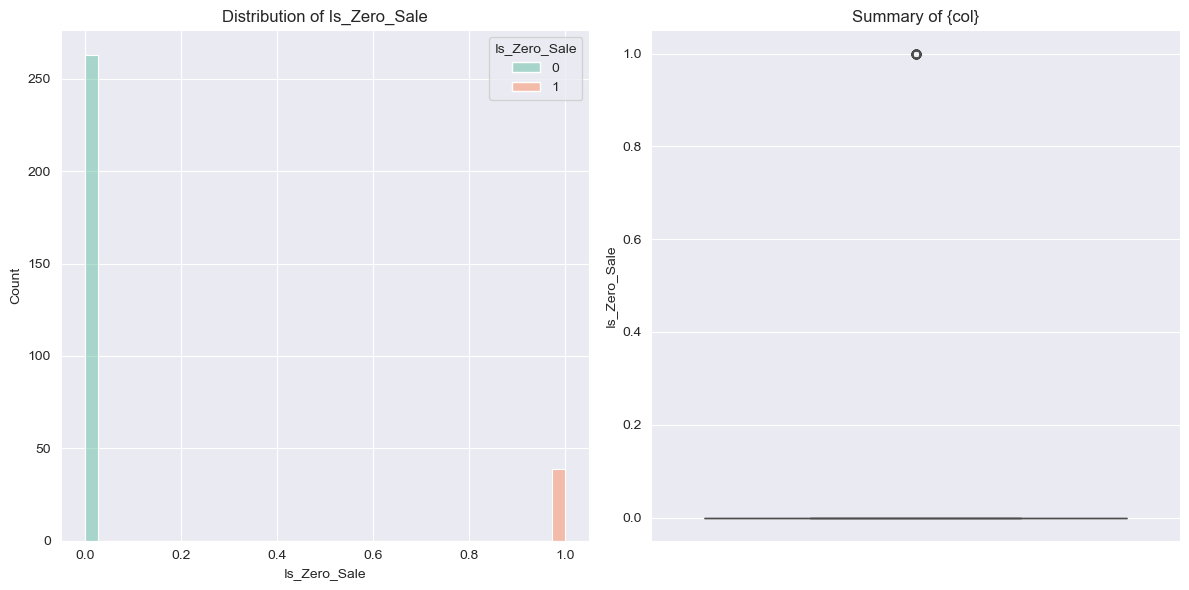

In [62]:
for col in numeric_cols:
    plt.figure(figsize = (12, 6))
    plt.subplot(1,2 , 1)
    sns.histplot(data = merged_df , x = col , hue = col , palette = 'Set2')
    plt.title(f"Distribution of {col}")

    plt.subplot(1,2,2)
    sns.boxplot(merged_df[col] , color = 'red')
    plt.title("Summary of {col}")

    plt.tight_layout()
    plt.show()

In [63]:
market_df

,Campaign_ID,Channel,Date,Reach,CTR (%),Reach_Clean,M_Day,M_Weekday,M_Month,M_Year,CTR_Percent
0,MKT1,YouTube Campaign,NaT,5000.0,NaN,5000.0,NaN,NaN,NaN,NaN,NaN
1,MKT2,Email,2025-02-15,-500.0,4%,0.0,15.0,5.0,2.0,2025.0,4.0
2,MKT3,Facebook Ads,2025-02-08,12000.0,0.02,12000.0,8.0,5.0,2.0,2025.0,2.0
3,MKT4,Email,NaT,5000.0,3.5%,5000.0,NaN,NaN,NaN,NaN,3.5
4,NaN,YouTube Campaign,NaT,-500.0,0.02,0.0,NaN,NaN,NaN,NaN,2.0
...,...,...,...,...,...,...,...,...,...,...,...
145,MKT146,Google Ads,2025-02-15,10000.0,4%,10000.0,15.0,5.0,2.0,2025.0,4.0
146,MKT147,YouTube Campaign,NaT,5000.0,2%,5000.0,NaN,NaN,NaN,NaN,2.0
147,MKT148,InstaAds,2025-02-15,-500.0,3.00%,0.0,15.0,5.0,2.0,2025.0,3.0
148,MKT149,YouTube Campaign,2025-01-22,5000.0,0.02,5000.0,22.0,2.0,1.0,2025.0,2.0


In [64]:
num_market = market_df.select_dtypes(include = np.number).columns.tolist()
cat_market = market_df.select_dtypes(include = 'object').columns.tolist()

In [65]:
market_df[num_market].isna().sum()

Reach          24
Reach_Clean     0
M_Day          44
M_Weekday      44
M_Month        44
M_Year         44
CTR_Percent    18
dtype: int64

In [66]:
market_df["Campaign_ID"] = market_df["Campaign_ID"].fillna(
    pd.Series(
        [f"MKT{i}" for i in range(1, len(market_df) + 1)],
        index = market_df.index
    )
)

In [67]:
market_df

,Campaign_ID,Channel,Date,Reach,CTR (%),Reach_Clean,M_Day,M_Weekday,M_Month,M_Year,CTR_Percent
0,MKT1,YouTube Campaign,NaT,5000.0,NaN,5000.0,NaN,NaN,NaN,NaN,NaN
1,MKT2,Email,2025-02-15,-500.0,4%,0.0,15.0,5.0,2.0,2025.0,4.0
2,MKT3,Facebook Ads,2025-02-08,12000.0,0.02,12000.0,8.0,5.0,2.0,2025.0,2.0
3,MKT4,Email,NaT,5000.0,3.5%,5000.0,NaN,NaN,NaN,NaN,3.5
4,MKT5,YouTube Campaign,NaT,-500.0,0.02,0.0,NaN,NaN,NaN,NaN,2.0
...,...,...,...,...,...,...,...,...,...,...,...
145,MKT146,Google Ads,2025-02-15,10000.0,4%,10000.0,15.0,5.0,2.0,2025.0,4.0
146,MKT147,YouTube Campaign,NaT,5000.0,2%,5000.0,NaN,NaN,NaN,NaN,2.0
147,MKT148,InstaAds,2025-02-15,-500.0,3.00%,0.0,15.0,5.0,2.0,2025.0,3.0
148,MKT149,YouTube Campaign,2025-01-22,5000.0,0.02,5000.0,22.0,2.0,1.0,2025.0,2.0


In [70]:
num_market = ['Reach_Clean' , "CTR_Percent"]

In [71]:
imputer_market = KNNImputer(n_neighbors = 5 , weights = 'uniform')
market_df[num_market] = imputer_market.fit_transform(market_df[num_market])

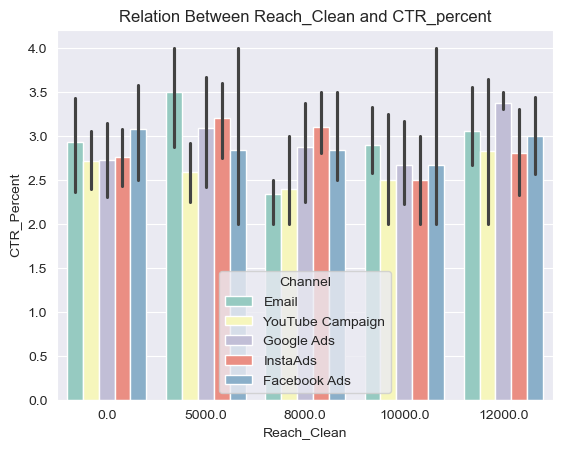

In [76]:
sns.barplot(data = market_df , x = 'Reach_Clean' , y= 'CTR_Percent' , hue = 'Channel' , palette = 'Set3')
plt.title("Relation Between Reach_Clean and CTR_percent")
plt.show()

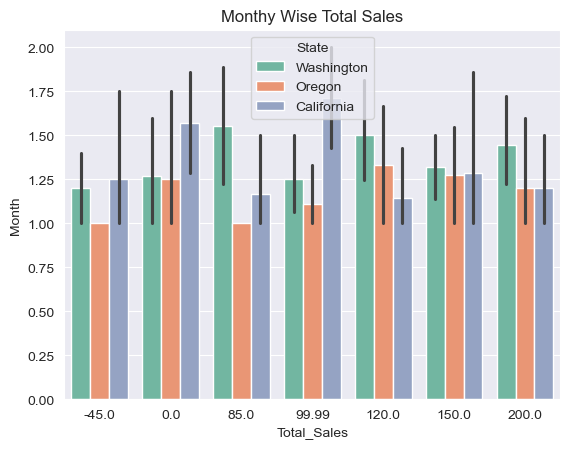

In [77]:
sns.barplot(data = merged_df , x = 'Total_Sales' , y = 'Month' , hue = 'State',  palette = 'Set2')
plt.title("Monthy Wise Total Sales")
plt.show()

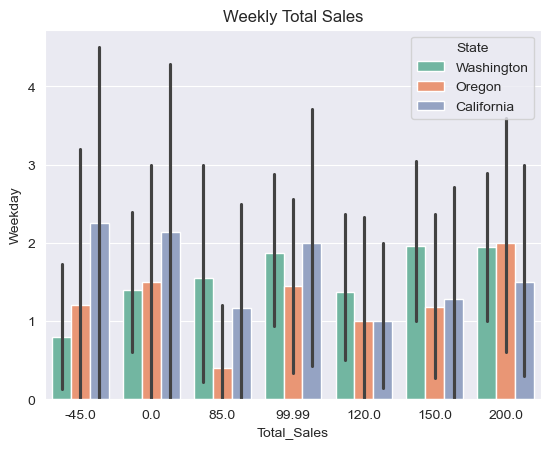

In [78]:
sns.barplot(data = merged_df , x = 'Total_Sales' , y = 'Weekday' , hue = 'State',  palette = 'Set2')
plt.title("Weekly Total Sales")
plt.show()

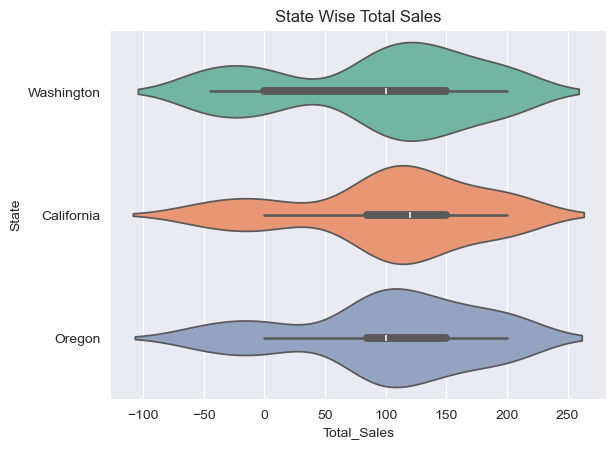

In [79]:
sns.violinplot(data = merged_df , x = 'Total_Sales' , y = 'State' , hue = 'State',  palette = 'Set2')
plt.title("State Wise Total Sales")
plt.show()

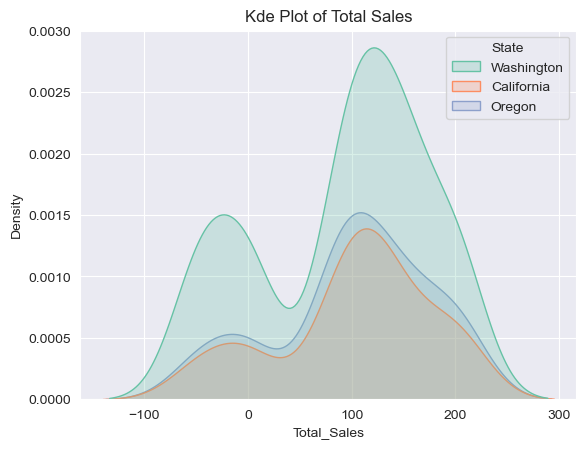

In [80]:
sns.kdeplot(data = merged_df , x = 'Total_Sales' , hue = 'State' , fill = True , palette = 'Set2')
plt.title("Kde Plot of Total Sales")
plt.show()

In [81]:
merged_df

,Order_ID,Customer_ID,Order_Date,Total_Sales,Cust_ID,Customer_Name,State,Day,Weekday,Month,Year,Is_Refund,Is_Zero_Sale
0,ORD1000,CUST195,2025-01-13,-45.0,CUST195,Alice Green,Washington,13.0,0.0,1.0,2025.0,1,0
1,ORD1001,NaN,2025-01-13,0.0,NaN,NaN,Washington,13.0,0.0,1.0,2025.0,0,1
2,ORD1002,NaN,NaT,150.0,NaN,NaN,Washington,NaN,NaN,NaN,NaN,0,0
3,ORD1003,CUST184,NaT,85.0,CUST184,Bob White,California,NaN,NaN,NaN,NaN,0,0
4,ORD1004,CUST168,2025-02-12,120.0,CUST168,Charlie Tan,California,12.0,2.0,2.0,2025.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,ORD1295,NaN,NaT,150.0,NaN,NaN,Washington,NaN,NaN,NaN,NaN,0,0
298,ORD1296,CUST155,2025-01-22,150.0,CUST155,Fred Stone,California,22.0,2.0,1.0,2025.0,0,0
299,ORD1297,CUST019,NaT,-45.0,CUST019,Eve Gray,California,NaN,NaN,NaN,NaN,1,0
300,ORD1298,CUST089,2025-02-17,120.0,CUST089,Charlie Tan,Washington,17.0,0.0,2.0,2025.0,0,0


In [82]:
inventory_df

,SKU,Product_Name,Stock,Unit_Price,Price_amount,Currency,Exchange_Rate,Unit_Price_INR,Product_Number
0,SKU1,Product 1,100.0,$25,25.0,USD,93.4798,2336.9950,1
1,SKU2,Product 2,0.0,€20,20.0,EUR,102.7270,2054.5400,2
2,SKU3,Product 3,9999.0,£18,18.0,GBP,123.2970,2219.3460,3
3,SKU4,Product 4,100.0,$30,30.0,USD,93.4798,2804.3940,4
4,SKU5,Product 5,0.0,$30,30.0,USD,93.4798,2804.3940,5
...,...,...,...,...,...,...,...,...,...
95,SKU96,Product 96,0.0,AUD$26,26.0,AUD,62.9849,1637.6074,96
96,SKU97,Product 97,9999.0,USD 28,28.0,USD,93.4798,2617.4344,97
97,SKU98,Product 98,0.0,AUD$26,26.0,AUD,62.9849,1637.6074,98
98,SKU99,Product 99,50.0,$30,30.0,USD,93.4798,2804.3940,99


In [83]:
market_df

,Campaign_ID,Channel,Date,Reach,CTR (%),Reach_Clean,M_Day,M_Weekday,M_Month,M_Year,CTR_Percent
0,MKT1,YouTube Campaign,NaT,5000.0,NaN,5000.0,NaN,NaN,NaN,NaN,3.0
1,MKT2,Email,2025-02-15,-500.0,4%,0.0,15.0,5.0,2.0,2025.0,4.0
2,MKT3,Facebook Ads,2025-02-08,12000.0,0.02,12000.0,8.0,5.0,2.0,2025.0,2.0
3,MKT4,Email,NaT,5000.0,3.5%,5000.0,NaN,NaN,NaN,NaN,3.5
4,MKT5,YouTube Campaign,NaT,-500.0,0.02,0.0,NaN,NaN,NaN,NaN,2.0
...,...,...,...,...,...,...,...,...,...,...,...
145,MKT146,Google Ads,2025-02-15,10000.0,4%,10000.0,15.0,5.0,2.0,2025.0,4.0
146,MKT147,YouTube Campaign,NaT,5000.0,2%,5000.0,NaN,NaN,NaN,NaN,2.0
147,MKT148,InstaAds,2025-02-15,-500.0,3.00%,0.0,15.0,5.0,2.0,2025.0,3.0
148,MKT149,YouTube Campaign,2025-01-22,5000.0,0.02,5000.0,22.0,2.0,1.0,2025.0,2.0


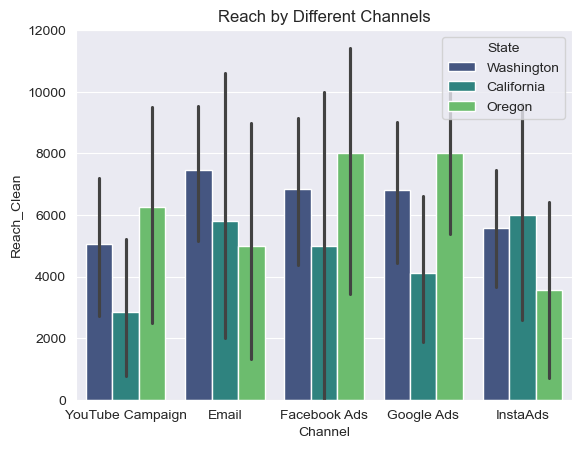

In [84]:
sns.barplot(x = market_df.Channel , y = market_df.Reach_Clean , hue = merged_df.State , palette = 'viridis')
plt.title("Reach by Different Channels")
plt.show()

In [93]:
inventory_df

,SKU,Product_Name,Stock,Unit_Price_INR
0,SKU1,Product 1,100.0,2336.9950
1,SKU2,Product 2,0.0,2054.5400
2,SKU3,Product 3,9999.0,2219.3460
3,SKU4,Product 4,100.0,2804.3940
4,SKU5,Product 5,0.0,2804.3940
...,...,...,...,...
95,SKU96,Product 96,0.0,1637.6074
96,SKU97,Product 97,9999.0,2617.4344
97,SKU98,Product 98,0.0,1637.6074
98,SKU99,Product 99,50.0,2804.3940


In [ ]:
merged_df.drop(columns = ['Cust_ID '] , inplace = True)
inventory_df.drop(columns = ['Unit_Price' , 'Price_amount' , 'Currency' , 'Exchange_Rate' , 'Product_Number'] , inplace = True)
market_df.drop(columns = ["Reach" , "CTR (%)"] , inplace =True)

In [95]:
import os
data_path = 'XPro'

os.makedirs(data_path , exist_ok = True)

In [96]:
merged_df.to_csv(os.path.join(data_path , "Merged.csv") , index= False)
inventory_df.to_csv(os.path.join(data_path , "inventory.csv") , index = False)
market_df.to_csv(os.path.join(data_path , "market.csv") , index = True)